# 🚑 EMS Capacity Planning — Từ dự báo 24 giờ tới đến số xe cứu thương mỗi ca

**Câu hỏi vận hành:** cuối mỗi ngày, cần xếp **bao nhiêu xe trực cho từng ca của ngày hôm sau**, và kế hoạch đó **đủ xe đến đâu** so với nhu cầu thực tế?

### Quy trình
| Bước | Nội dung |
|---|---|
| 1 | Nạp **dự báo 24 giờ tới** (day-ahead) của LSTM 24h-block, SARIMAX và Prophet 24h, cùng baseline profile lịch sử 2025. Dự báo 1 giờ tới **không** dùng được để xếp ca trước. |
| 2 | Tham số thời gian bận từ dữ liệu thô 2025: $E[S]$ = 63,38 phút/lượt xe và **kernel lan tỏa** (xe bận xuyên giờ). |
| 3 | **Khối lượng công việc** $W(h) = \sum_k \hat{\lambda}(h-k)\,p_k$ và số xe $s(h) = \lceil W(h)/\rho_{max} \rceil$, với $\rho_{max}$ = 75% / 80% / 85% (kịch bản, chưa phải tiêu chuẩn). |
| 4 | **Số xe thực cần** $s^*(h)$: đưa số lượt điều xe **thực tế 2026** qua đúng công thức trên → thước đo chung để chấm mọi kế hoạch. |
| 5 | Lập kế hoạch theo **dự báo trung bình**, theo **cận trên P90**, và tìm **phân vị tối ưu** theo tỷ lệ chi phí thiếu/thừa. |
| 6 | Quy đổi sang **ca trực** (3 ca × 8h, 2 ca × 12h), mỗi ca lấy mức cao nhất trong ca. |
| 7 | Đánh giá: xe-giờ bố trí, xe-giờ thiếu/thừa, % giờ và % ca thiếu xe, chi phí tương đối. |

> **Lưu ý dữ liệu:** `call_count` trong `y_*.csv` khớp 100% với **số lượt điều xe MEDIC** mỗi giờ (không phải số cuộc gọi duy nhất), nên $\hat{\lambda}$ đã gồm mọi xe được điều → không nhân thêm số xe/cuộc gọi.

### 📖 Thuật ngữ dùng trong notebook

| Thuật ngữ | Nghĩa trong bài toán xe cứu thương | Ví dụ |
|---|---|---|
| **Lượt điều xe** $\lambda(h)$ | Số lần một xe MEDIC được điều đi trong giờ $h$ (cột `call_count`) | Trung bình 2026 ≈ 11–12 lượt/giờ |
| **Thời gian bận** $E[S]$ | Từ lúc xe được điều đến lúc xe sẵn sàng nhận ca mới | 63,38 phút ≈ 1 giờ |
| **Khối lượng công việc** $W(h)$ | **Số xe đang bận trung bình** trong giờ $h$ | $W = 12$: tại một thời điểm bất kỳ trong giờ đó, trung bình 12 xe đang làm nhiệm vụ |
| **Mức bận tối đa** $\rho_{max}$ | Mỗi xe chỉ được bận tối đa bao nhiêu % thời gian; phần còn lại là **dự phòng** cho lúc cuộc gọi dồn dập | $\rho = 80\%$, $W = 12$ → cần $12/0{,}8 = 15$ xe (3 xe dự phòng) |
| **Số xe thực cần** $s^*(h)$ | Số xe *lẽ ra* phải có nếu biết trước chính xác nhu cầu (tính từ số thực tế 2026) | Dùng làm "đáp án" để chấm kế hoạch |
| **Kế hoạch** $s(h)$ | Số xe xếp **trước** dựa trên dự báo | |
| **Xe-giờ** | 1 xe trực trong 1 giờ — đơn vị đo nguồn lực | 1 ca 8h × 20 xe = 160 xe-giờ |
| **Xe-giờ thiếu** | Tổng $(s^* - s)$ ở những giờ kế hoạch **ít hơn** thực cần → **rủi ro**: cuộc gọi phải chờ, phải điều xe ở xa | |
| **Xe-giờ thừa** | Tổng $(s - s^*)$ ở những giờ kế hoạch **nhiều hơn** thực cần → **lãng phí** | |
| **Phân vị** $P_q$ | Mức dự báo mà số thực tế chỉ vượt quá trong $(1-q)$ số giờ | P90: chỉ khoảng 10% số giờ thực tế cao hơn mức này |
| **Tỷ lệ chi phí** $r$ | 1 xe-giờ thiếu "đắt" bằng bao nhiêu xe-giờ thừa | $r = 3$: thiếu 1 xe-giờ tệ như thừa 3 xe-giờ |

**Cell dưới:** nạp thư viện và **đặt các kịch bản**. Muốn thử kịch bản khác (ví dụ $\rho$ = 85%, hoặc coi thiếu xe đắt gấp 10 lần) chỉ cần sửa các biến `RHO_BASE`, `COST_RATIO`… ở đây rồi **Run All**: mọi bảng và phần tóm tắt sẽ tự cập nhật.

In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd().resolve()
if not (ROOT / "ems").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "ems").is_dir():
    raise RuntimeError("Run from project root or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)

from ems.data import load_data
from ems.evaluation import compute_metrics
from ems.paths import OUTPUT_DIR as SHARED_OUTPUT_DIR
from ems.models.lstm.config import N_FEATURES, HIDDEN_SIZE, NUM_LAYERS, DROPOUT, BATCH_SIZE
from ems.models.lstm.preprocess import (build_block_dataloaders, load_data as lstm_load_data,
                                        load_scalers, scale_data, create_block_sequences,
                                        make_dataloader)
from ems.models.lstm.model import build_model
from ems.models.lstm.train import load_checkpoint
from ems.models.lstm.evaluate import predict_24h_blocks
from ems.queuing import (estimate_service_params, BUSY_KERNEL_2025, workload_from_rate,
                         vehicles_needed, vehicles_erlang_b, vehicles_poisson_quantile,
                         SHIFT_PATTERNS, shift_plan, evaluate_plan)

# ── Cấu hình kịch bản ────────────────────────────────────────────────────────
RHO_LIST   = [0.75, 0.80, 0.85]   # mức bận trung bình tối đa cho phép (kịch bản)
RHO_BASE   = 0.80                 # mức dùng cho các bảng/biểu đồ chính
Q_UPPER    = 0.90                 # cận trên dự báo dùng cho kế hoạch "P90"
COST_RATIO = 3                    # 1 xe-giờ thiếu "đắt" gấp mấy lần 1 xe-giờ thừa (kịch bản chính)
COST_RATIOS = (2, 3, 5, 10, 20)  # các kịch bản tỷ lệ chi phí thiếu / thừa
LSTM_RUN   = "vanilla_24h_block"
# File dự báo SARIMAX khớp với checkpoints/sarimax/metadata.json (MAE test 2,997)
SARIMAX_PRED = ROOT / "outputs" / "sarimax" / "rerun" / "pred_sarimax.csv"
# Prophet 24h từ nhánh feat/prophet-24h (cấu hình chọn theo validation 24h)
PROPHET_TEST = ROOT / "outputs" / "prophet" / "day_ahead_24h" / "test_selected" / "predictions_24h.csv"
PROPHET_VAL  = ROOT / "outputs" / "prophet" / "day_ahead_24h" / "selection" / "best_validation_predictions.csv"

OUT_DIR = SHARED_OUTPUT_DIR / "queuing"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUT_DIR)

Output dir: F:\ems-forecast\outputs\queuing


## Bước 1: Nạp dữ liệu và dự báo 24 giờ tới

Cả ba nguồn đều là dự báo **lập trước cho cả ngày hôm sau**, không quan sát số thực trong ngày:

| Nguồn | Dự báo trung bình | Cận trên P90 |
|---|---|---|
| **Profile 2025 (giờ × thứ)** — baseline | Trung bình 2025 theo (giờ, thứ) | Phân vị 90% của 2025 theo (giờ, thứ) |
| **SARIMAX 24h** | `pred` | `hi` = đầu trên khoảng 80% của mô hình (danh nghĩa là P90) |
| **LSTM 24h block** | Đầu ra mô hình | Dự báo + phân vị 90% sai số trên **validation 2025** theo giờ trong ngày |
| **Prophet 24h** (nhánh `feat/prophet-24h`) | Dự báo đệ quy phát hành lúc 00h | Như LSTM: dự báo + phân vị sai số validation 2025 theo giờ |

Mọi cận trên đều chỉ dùng thông tin đến hết 2025 (không nhìn dữ liệu test).

**Vì sao cần cận trên?** Dự báo trung bình chỉ đúng "trung bình": khoảng một nửa số giờ thực tế sẽ **cao hơn** dự báo. Nếu xếp xe theo dự báo trung bình, gần một nửa thời gian sẽ hụt xe. Cận trên P90 là mức "phòng xa" mà chỉ khoảng 10% số giờ vượt quá.

**Cell dưới:** đọc số lượt điều xe thực tế năm 2025 (validation, dùng để học/hiệu chỉnh) và 2026 (test, dùng để chấm điểm), tạo baseline Profile 2025 và nạp dự báo SARIMAX đã lưu.

In [2]:
splits = load_data()
y_val  = splits["val"].set_index("ds")["y"].astype(float)
y_test = splits["test"].set_index("ds")["y"].astype(float)
ts_test = y_test.index
print(f"Validation: {y_val.index[0]} → {y_val.index[-1]}  ({len(y_val):,} giờ)")
print(f"Test      : {ts_test[0]} → {ts_test[-1]}  ({len(y_test):,} giờ)")

mean_fc, upper_fc = {}, {}

# ── Baseline: profile 2025 theo (giờ, thứ) ───────────────────────────────────
key_val  = [y_val.index.hour, y_val.index.dayofweek]
key_test = list(zip(ts_test.hour, ts_test.dayofweek))
prof_mean = y_val.groupby(key_val).mean()
prof_q    = y_val.groupby(key_val).quantile(Q_UPPER)
mean_fc["Profile 2025"]  = np.array([prof_mean[k] for k in key_test])
upper_fc["Profile 2025"] = np.array([prof_q[k] for k in key_test])

# ── SARIMAX 24h ───────────────────────────────────────────────────────────────
sar = pd.read_csv(SARIMAX_PRED, parse_dates=["timestamp"]).set_index("timestamp")
assert sar.index.equals(ts_test) and np.array_equal(sar["actual"].values, y_test.values), "SARIMAX lệch giờ test"
mean_fc["SARIMAX 24h"]  = sar["pred"].values
upper_fc["SARIMAX 24h"] = sar["hi"].values
print("SARIMAX: đã nạp", SARIMAX_PRED.relative_to(ROOT))
print(f"\nTrung bình 2025: {y_val.mean():.2f} lượt/giờ | 2026: {y_test.mean():.2f} lượt/giờ "
      f"| giờ cao nhất 2026: {y_test.max():.0f} lượt")

Validation: 2025-01-01 00:00:00 → 2025-12-31 23:00:00  (8,760 giờ)
Test      : 2026-01-01 00:00:00 → 2026-10-11 03:00:00  (6,796 giờ)
SARIMAX: đã nạp outputs\sarimax\rerun\pred_sarimax.csv

Trung bình 2025: 11.45 lượt/giờ | 2026: 11.68 lượt/giờ | giờ cao nhất 2026: 40 lượt


**Cell dưới:** chạy lại mô hình LSTM 24h block (đã huấn luyện, không train lại) trên **cả năm 2025 và 2026**. Dự báo 2025 dùng để đo xem LSTM thường sai bao nhiêu ở mỗi giờ trong ngày → từ đó dựng cận trên cho 2026. Nạp thêm dự báo Prophet 24h (nếu có file), rồi chấm độ chính xác của cả 4 nguồn trên 2026.

In [3]:
# ── LSTM 24h block: test ─────────────────────────────────────────────────────
_, _, test_dl, _, tgt_scaler = build_block_dataloaders(seq_len=24, horizon=24,
                                                       batch_size=BATCH_SIZE, verbose=False)
model_24b = build_model("vanilla", n_features=N_FEATURES, hidden_size=HIDDEN_SIZE,
                        num_layers=NUM_LAYERS, dropout=DROPOUT, forecast_horizon=24)
load_checkpoint(model_24b, run_name=LSTM_RUN)
yt_true, yt_pred = predict_24h_blocks(model_24b, test_dl, tgt_scaler, n_target_hours=len(y_test))
assert np.allclose(yt_true, y_test.values), "LSTM lệch giờ test"

# ── LSTM 24h block: validation 2025 (cùng cách chạy theo khối 24h) ────────────
X_tr, y_tr, X_va, y_va, _, _ = lstm_load_data()
feat_scaler, tgt_scaler = load_scalers()
X_tr_sc, y_tr_sc = scale_data(X_tr, y_tr, feat_scaler, tgt_scaler)
X_va_sc, y_va_sc = scale_data(X_va, y_va, feat_scaler, tgt_scaler)
X_ctx = np.concatenate([X_tr_sc[-24:], X_va_sc]); y_ctx = np.concatenate([y_tr_sc[-24:], y_va_sc])
Xs, ys = create_block_sequences(X_ctx, y_ctx, seq_len=24, horizon=24, step=24)
yv_true, yv_pred = predict_24h_blocks(model_24b, make_dataloader(Xs, ys, BATCH_SIZE),
                                      tgt_scaler, n_target_hours=len(y_val))
assert np.allclose(yv_true, y_val.values), "LSTM lệch giờ validation"

# Cận trên = dự báo + phân vị 90% của sai số validation theo giờ trong ngày
lstm_resid = pd.Series(yv_true - yv_pred, index=y_val.index)
mean_fc["LSTM 24h block"] = yt_pred

# ── Prophet 24h (nhánh feat/prophet-24h): dự báo đệ quy phát hành lúc 00h ─────
# Cấu hình chọn theo MAE validation 24h; fit train đến hết 2024, không refit.
resid_by_model = {"LSTM 24h block": lstm_resid}
if PROPHET_TEST.exists() and PROPHET_VAL.exists():
    pt = pd.read_csv(PROPHET_TEST, parse_dates=["ds"]).set_index("ds")
    pv = pd.read_csv(PROPHET_VAL, parse_dates=["ds"]).set_index("ds")
    assert pt.index.equals(ts_test) and np.array_equal(pt["y"].values, y_test.values), "Prophet lệch giờ test"
    assert pv.index.equals(y_val.index) and np.array_equal(pv["y"].values, y_val.values), "Prophet lệch giờ validation"
    mean_fc["Prophet 24h"] = pt["yhat"].values
    resid_by_model["Prophet 24h"] = pd.Series(pv["y"].values - pv["yhat"].values, index=y_val.index)
    print("Prophet 24h: đã nạp", PROPHET_TEST.relative_to(ROOT))
else:
    print("⚠ Không thấy file dự báo Prophet 24h → bỏ qua Prophet (xem PROPHET_TEST/PROPHET_VAL)")

MODELS = list(mean_fc)

from statistics import NormalDist
_z90 = NormalDist().inv_cdf(0.90)

def quantile_fc(model, q):
    # Dự báo ở phân vị q, chỉ dùng thông tin đến hết 2025
    if model == "Profile 2025":
        prof = y_val.groupby(key_val).quantile(q)
        return np.array([prof[k] for k in key_test])
    if model == "SARIMAX 24h":   # xấp xỉ chuẩn từ khoảng 80% của mô hình
        sd = (sar["hi"].values - sar["pred"].values) / _z90
        return np.clip(sar["pred"].values + NormalDist().inv_cdf(q) * sd, 0, None)
    if model in resid_by_model:   # LSTM, Prophet: dự báo + phân vị sai số validation theo giờ
        res = resid_by_model[model]
        rq = res.groupby(res.index.hour).quantile(q)
        return np.clip(mean_fc[model] + rq.reindex(ts_test.hour).values, 0, None)
    raise KeyError(model)

for m in MODELS:
    upper_fc[m] = quantile_fc(m, Q_UPPER) if m != "SARIMAX 24h" else sar["hi"].values

# ── Độ chính xác dự báo & độ phủ cận trên trên test ──────────────────────────
rows = []
for m in MODELS:
    met = compute_metrics(y_test.values, mean_fc[m])
    met["Độ phủ P90 (%)"] = (y_test.values <= upper_fc[m]).mean() * 100
    rows.append({"Nguồn dự báo": m, **met})
acc = pd.DataFrame(rows).set_index("Nguồn dự báo")
from IPython.display import display
print("Độ chính xác dự báo 24h tới trên test 2026 (độ phủ P90 lý tưởng ≈ 90%):")
display(acc)

best_m = acc["MAE"].idxmin()
gap = (acc.loc["Profile 2025", "MAE"] - acc.loc[best_m, "MAE"]) / acc.loc["Profile 2025", "MAE"] * 100
print(f"💡 Diễn giải: nguồn chính xác nhất là {best_m} — trung bình mỗi giờ lệch {acc.loc[best_m, 'MAE']:.2f} lượt "
      f"(≈ {acc.loc[best_m, 'MAE'] / y_test.mean() * 100:.0f}% của mức trung bình {y_test.mean():.1f} lượt/giờ).")
print(f"   So với baseline Profile 2025, MAE chỉ tốt hơn {gap:.1f}% → các mô hình gần như ngang baseline.")
print(f"   R² ≈ {acc['R2'].max():.2f}: khoảng {100 - acc['R2'].max() * 100:.0f}% dao động từng giờ là ngẫu nhiên, "
      f"không mô hình nào đoán trước được → bắt buộc phải có xe dự phòng.")

[Load] Loaded 'vanilla_24h_block' | best_val_loss=0.00786


C:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


C:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Prophet 24h: đã nạp outputs\prophet\day_ahead_24h\test_selected\predictions_24h.csv


Độ chính xác dự báo 24h tới trên test 2026 (độ phủ P90 lý tưởng ≈ 90%):


,MAE,RMSE,MAPE (%),R2,Độ phủ P90 (%)
Nguồn dự báo,,,,,
Profile 2025,3.04,3.93,33.05,0.38,87.54
SARIMAX 24h,3.00,3.87,33.00,0.40,89.48
LSTM 24h block,3.01,3.86,33.97,0.40,88.67
Prophet 24h,3.05,3.97,32.75,0.36,87.99


💡 Diễn giải: nguồn chính xác nhất là SARIMAX 24h — trung bình mỗi giờ lệch 3.00 lượt (≈ 26% của mức trung bình 11.7 lượt/giờ).
   So với baseline Profile 2025, MAE chỉ tốt hơn 1.5% → các mô hình gần như ngang baseline.
   R² ≈ 0.40: khoảng 60% dao động từng giờ là ngẫu nhiên, không mô hình nào đoán trước được → bắt buộc phải có xe dự phòng.


#### 🔎 Cách đọc bảng độ chính xác
| Cột | Ý nghĩa | Đọc thế nào |
|---|---|---|
| **MAE** | Trung bình mỗi giờ, dự báo lệch bao nhiêu lượt điều xe | MAE = 3 → mỗi giờ lệch khoảng 3 lượt ≈ 3 xe-giờ bận. **Càng nhỏ càng tốt** |
| **RMSE** | Giống MAE nhưng phạt nặng các giờ lệch lớn | RMSE cao hơn MAE nhiều → có những giờ lệch rất mạnh (đột biến) |
| **MAPE (%)** | Sai số tính theo % của giá trị thực | Bị đẩy cao ở các giờ đêm ít cuộc gọi (chia cho số nhỏ) — không nên dùng một mình |
| **R2** | Tỷ lệ dao động mà mô hình giải thích được (0–1) | 0,4 → 60% dao động còn lại là "nhiễu" → chính là lý do cần $\rho$ và cận trên |
| **Độ phủ P90 (%)** | % số giờ mà thực tế **≤** cận trên P90 | Lý tưởng ≈ 90%. Thấp hơn (ví dụ 87%) → cận trên hơi "lạc quan", kế hoạch P90 sẽ thiếu xe nhiều hơn dự kiến một chút |

**Ý nghĩa cho bài toán:** độ chính xác dự báo chỉ là bước đầu. Hai mô hình có MAE chênh 0,01 có thể dẫn tới số xe gần như giống hệt nhau, nên các bước sau mới là phần quyết định.

## Bước 2: Thời gian xe bận và kernel bận xuyên giờ

* $E[S]$ = trung bình (`available_dttm` − `dispatch_dttm`) của 100.320 lượt điều xe MEDIC năm 2025 = **63,38 phút** (median 70,3; p90 110,6 phút).
* Một lượt điều xe không chỉ chiếm giờ nhận cuộc gọi mà **tràn sang các giờ sau**. Kernel $p_k$ = số xe-giờ bận trung bình một lượt điều xe đóng góp vào giờ $h+k$:

$$W(h) = \sum_{k \ge 0} \hat{\lambda}(h-k)\, p_k, \qquad \sum_k p_k \approx E[S]$$

Cách cũ ($a = \hat{\lambda} \times E[S]$) dồn toàn bộ thời gian bận vào giờ nhận cuộc gọi → lệch đỉnh nhu cầu khoảng 1 giờ.

[Queuing] Dùng tham số ước lượng từ raw 2025:
  E[S] = 3803 giây  = 1.0563 giờ
  u    = 1.0000 xe/cuộc gọi

Kernel p_k (xe-giờ / lượt điều xe): [3.605e-01 5.575e-01 1.267e-01 9.200e-03 1.500e-03 4.000e-04]
Tổng kernel = 1.0559 xe-giờ = 63.35 phút (E[S] = 63.38 phút)
Phần bận rơi vào chính giờ nhận cuộc gọi: 34.1%


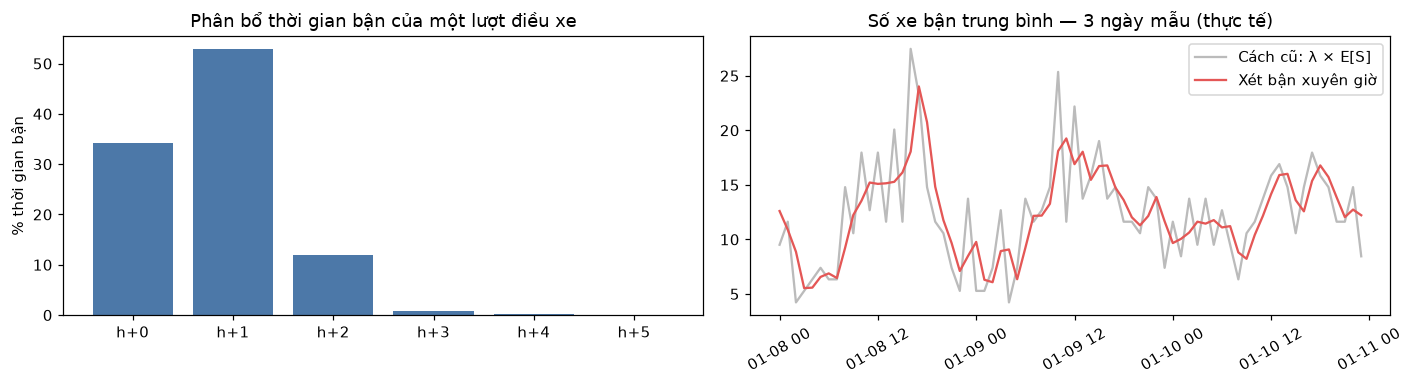

Tương quan theo giờ giữa hai cách: 0.757


In [4]:
params = estimate_service_params(raw_df=None)   # mặc định = ước lượng raw 2025
kernel = BUSY_KERNEL_2025
print(f"\nKernel p_k (xe-giờ / lượt điều xe): {np.round(kernel, 4)}")
print(f"Tổng kernel = {kernel.sum():.4f} xe-giờ = {kernel.sum() * 60:.2f} phút "
      f"(E[S] = {params['E_S_hr'] * 60:.2f} phút)")
print(f"Phần bận rơi vào chính giờ nhận cuộc gọi: {kernel[0] / kernel.sum() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].bar([f"h+{k}" for k in range(len(kernel))], kernel / kernel.sum() * 100, color="#4C78A8")
axes[0].set_title("Phân bổ thời gian bận của một lượt điều xe")
axes[0].set_ylabel("% thời gian bận")

# Ví dụ 3 ngày: tải theo cách cũ và cách xét bận xuyên giờ (trên số thực tế)
W_old = y_test.values * params["E_S_hr"]
W_new = workload_from_rate(y_test.values, kernel, history=y_val.values)
sl = slice(24 * 7, 24 * 10)
axes[1].plot(ts_test[sl], W_old[sl], label="Cách cũ: λ × E[S]", color="#BBBBBB")
axes[1].plot(ts_test[sl], W_new[sl], label="Xét bận xuyên giờ", color="#E45756")
axes[1].set_title("Số xe bận trung bình — 3 ngày mẫu (thực tế)")
axes[1].legend(); axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(OUT_DIR / "busy_kernel.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Tương quan theo giờ giữa hai cách: {np.corrcoef(W_old, W_new)[0, 1]:.3f}")

#### 🔎 Cách đọc
* **Biểu đồ trái (kernel):** một xe được điều trong giờ $h$ chỉ dành khoảng 1/3 thời gian bận ở chính giờ $h$; **hơn một nửa rơi vào giờ $h+1$**, phần còn lại sang $h+2$. Ví dụ: xe điều lúc 10:40, bận 63 phút → bận tới 11:43, nên phần lớn "chiếm chỗ" của giờ 11.
* **Biểu đồ phải:** đường đỏ (xét bận xuyên giờ) **trễ khoảng 1 giờ và mượt hơn** đường xám (cách cũ). Nếu dùng cách cũ, kế hoạch sẽ đưa xe vào cao điểm **sớm 1 giờ** và rút xe **sớm 1 giờ** — đúng lúc các xe điều ở cao điểm vẫn chưa về.
* **Tương quan ≈ 0,76:** tính trung bình cả năm thì hai cách như nhau, nhưng **từng giờ** khác nhau đáng kể → với bài toán xếp ca theo giờ, cách xét bận xuyên giờ là cần thiết.

## Bước 3: Số xe thực cần và kế hoạch theo giờ

* **Số xe thực cần** $s^*(h) = \lceil W^*(h) / \rho_{max} \rceil$, với $W^*$ tính từ số lượt điều xe **thực tế** 2026. Đây là thước đo chung để chấm mọi kế hoạch.
* **Kế hoạch** $s(h) = \lceil W(h) / \rho_{max} \rceil$, với $W$ tính từ **dự báo** (trung bình hoặc P90).
* Phần bận tràn từ cuối năm 2025 sang những giờ đầu 2026 dùng số thực tế 2025 (đã biết khi lập kế hoạch).

In [5]:
W_actual = workload_from_rate(y_test.values, kernel, history=y_val.values)
W_plan = {}
for m in MODELS:
    W_plan[(m, "Trung bình")] = workload_from_rate(mean_fc[m], kernel, history=y_val.values)
    W_plan[(m, "P90")]        = workload_from_rate(upper_fc[m], kernel, history=y_val.values)

need = {rho: vehicles_needed(W_actual, rho) for rho in RHO_LIST}

hourly_rows, hourly_plans = [], {}
for rho in RHO_LIST:
    for (m, basis), W in W_plan.items():
        plan = vehicles_needed(W, rho)
        hourly_plans[(m, basis, rho)] = plan
        hourly_rows.append({"Nguồn dự báo": m, "Kế hoạch theo": basis, "ρ_max": rho,
                            **evaluate_plan(plan, need[rho], cost_ratios=COST_RATIOS)})
eval_hourly = pd.DataFrame(hourly_rows)
eval_hourly.to_csv(OUT_DIR / "evaluation_hourly.csv", index=False)

cols = ["Xe-giờ bố trí", "Xe-giờ thiếu", "Xe-giờ thừa", "% giờ thiếu xe",
        "Thiếu TB khi thiếu (xe)", f"Chi phí (thiếu = {COST_RATIO}× thừa)"]
print(f"Số xe thực cần (ρ = {RHO_BASE:.0%}): TB {need[RHO_BASE].mean():.1f} xe, "
      f"thấp nhất {need[RHO_BASE].min()}, cao nhất {need[RHO_BASE].max()}")
print(f"\nĐánh giá kế hoạch THEO GIỜ, ρ = {RHO_BASE:.0%}:")
tbl = eval_hourly[eval_hourly["ρ_max"] == RHO_BASE].set_index(["Nguồn dự báo", "Kế hoạch theo"])[cols]
display(tbl)
n_h = len(ts_test)
mean_rows = tbl.xs("Trung bình", level=1); p90_rows = tbl.xs("P90", level=1)
print(f"💡 Diễn giải ({n_h:,} giờ test): nếu biết trước chính xác, trung bình cần {need[RHO_BASE].sum() / n_h:.1f} xe/giờ.")
print(f"   • Theo dự báo trung bình: bố trí ≈ {mean_rows['Xe-giờ bố trí'].mean() / n_h:.1f} xe/giờ nhưng vẫn thiếu xe ở "
      f"{mean_rows['% giờ thiếu xe'].min():.0f}–{mean_rows['% giờ thiếu xe'].max():.0f}% số giờ.")
print(f"   • Theo P90: bố trí ≈ {p90_rows['Xe-giờ bố trí'].mean() / n_h:.1f} xe/giờ, chỉ còn thiếu ở "
      f"{p90_rows['% giờ thiếu xe'].min():.1f}–{p90_rows['% giờ thiếu xe'].max():.1f}% số giờ — đổi lại thừa nhiều xe-giờ hơn.")

Số xe thực cần (ρ = 80%): TB 15.9 xe, thấp nhất 2, cao nhất 40

Đánh giá kế hoạch THEO GIỜ, ρ = 80%:


Xe-giờ bố trí  Xe-giờ thiếu  Xe-giờ thừa  % giờ thiếu xe  Thiếu TB khi thiếu (xe)  Chi phí (thiếu = 3× thừa)
Nguồn dự báo   Kế hoạch theo                                                                                                              
Profile 2025   Trung bình        106,107.00     10,190.00     8,137.00           45.62                     3.29                  38,707.00
               P90               147,769.00        856.00    40,465.00            4.64                     2.72                  43,033.00
SARIMAX 24h    Trung bình        107,007.00      9,583.00     8,430.00           43.13                     3.27                  37,179.00
               P90               151,330.00        598.00    43,768.00            3.28                     2.68                  45,562.00
LSTM 24h block Trung bình        108,199.00      9,024.00     9,063.00           41.10                     3.23                  36,135.00
               P90               150,864.00        637.00    43,341.00            3.56                     2.63                  45,252.00
Prophet 24h    Trung bình        102,995.00     11,982.00     6,817.00           49.21                     3.58                  42,763.00
               P90               149,988.00        774.00    42,602.00            4.28                     2.66                  44,924.00

💡 Diễn giải (6,796 giờ test): nếu biết trước chính xác, trung bình cần 15.9 xe/giờ.
   • Theo dự báo trung bình: bố trí ≈ 15.6 xe/giờ nhưng vẫn thiếu xe ở 41–49% số giờ.
   • Theo P90: bố trí ≈ 22.1 xe/giờ, chỉ còn thiếu ở 3.3–4.6% số giờ — đổi lại thừa nhiều xe-giờ hơn.


#### 🔎 Cách đọc bảng (kế hoạch theo từng giờ, chưa chia ca)
Mỗi dòng là một **cách xếp xe**: nguồn dự báo × dựa trên dự báo trung bình hay P90. Mọi dòng được chấm với **cùng một đáp án** (số xe thực cần).

| Cột | Ý nghĩa |
|---|---|
| **Xe-giờ bố trí** | Tổng nguồn lực bỏ ra cả giai đoạn test. Chia cho số giờ (6.796) = số xe trung bình mỗi giờ |
| **Xe-giờ thiếu** | Tổng số "xe còn thiếu" cộng dồn qua các giờ kế hoạch thấp hơn thực cần → **rủi ro cho bệnh nhân** |
| **Xe-giờ thừa** | Tổng số xe dư cộng dồn → **chi phí lãng phí** |
| **% giờ thiếu xe** | Tỷ lệ số giờ có ít nhất 1 xe bị thiếu |
| **Thiếu TB khi thiếu (xe)** | Khi đã thiếu thì thường thiếu mấy xe |
| **Chi phí** | Xe-giờ thừa + $r$ × xe-giờ thiếu (đơn vị tương đối, không phải tiền) |

**Ý nghĩa:** kế hoạch theo dự báo trung bình thiếu xe ở một tỷ lệ lớn số giờ, vì sai số dự báo (≈ 3 lượt/giờ) lớn hơn phần dự phòng mà $\rho_{max}$ tạo ra. Kế hoạch P90 bỏ thêm nguồn lực để gần như hết thiếu xe. Phương án nào "tốt hơn" phụ thuộc vào việc thiếu xe đắt gấp bao nhiêu lần thừa xe (xem Bước 5 và 7). Thực tế không thể đổi số xe **từng giờ**, nên bảng này chỉ để tham khảo; Bước 4 mới là kế hoạch dùng được.

## Bước 4: Quy đổi sang ca trực

Mỗi ca nhận số xe = **mức cao nhất** của kế hoạch theo giờ trong ca (phương án cơ sở, an toàn). Số xe thực cần vẫn chấm **theo từng giờ**, nên một ca bị tính là "thiếu" nếu có ít nhất một giờ trong ca thiếu xe.

In [6]:
shift_rows, shift_tables = [], {}
for pattern, (start, length) in SHIFT_PATTERNS.items():
    for rho in RHO_LIST:
        for (m, basis), _ in W_plan.items():
            plan_h, sid = shift_plan(ts_test, hourly_plans[(m, basis, rho)], start, length)
            shift_tables[(pattern, m, basis, rho)] = (plan_h, sid)
            shift_rows.append({"Kiểu ca": pattern, "Nguồn dự báo": m, "Kế hoạch theo": basis,
                               "ρ_max": rho, **evaluate_plan(plan_h.values, need[rho], sid.values, cost_ratios=COST_RATIOS)})
eval_shift = pd.DataFrame(shift_rows)
eval_shift.to_csv(OUT_DIR / "evaluation_shifts.csv", index=False)

cols_s = ["Xe-giờ bố trí", "Xe-giờ thiếu", "Xe-giờ thừa", "% giờ thiếu xe", "% ca có giờ thiếu",
          f"Chi phí (thiếu = {COST_RATIO}× thừa)"]
print(f"Đánh giá kế hoạch THEO CA, ρ = {RHO_BASE:.0%}:")
tbl_s = (eval_shift[eval_shift["ρ_max"] == RHO_BASE]
         .set_index(["Kiểu ca", "Nguồn dự báo", "Kế hoạch theo"])[cols_s])
display(tbl_s)
p8, p12 = list(SHIFT_PATTERNS)
c8 = tbl_s.xs(p8, level=0)[f"Chi phí (thiếu = {COST_RATIO}× thừa)"].mean()
c12 = tbl_s.xs(p12, level=0)[f"Chi phí (thiếu = {COST_RATIO}× thừa)"].mean()
print(f"💡 Diễn giải: chia 3 ca × 8h có chi phí trung bình thấp hơn 2 ca × 12h khoảng {(1 - c8 / c12) * 100:.0f}% "
      f"— ca ngắn bám sát nhu cầu hơn nên ít xe ngồi chờ ở các giờ vắng.")

Đánh giá kế hoạch THEO CA, ρ = 80%:


Xe-giờ bố trí  Xe-giờ thiếu  Xe-giờ thừa  % giờ thiếu xe  % ca có giờ thiếu  Chi phí (thiếu = 3× thừa)
Kiểu ca                         Nguồn dự báo   Kế hoạch theo                                                                                                        
3 ca × 8h (07–15, 15–23, 23–07) Profile 2025   Trung bình        126,864.00      4,528.00    23,232.00           20.85              69.29                  36,816.00
                                               P90               173,121.00        271.00    65,232.00            1.38               7.53                  66,045.00
                                SARIMAX 24h    Trung bình        125,928.00      4,799.00    22,567.00           21.54              68.82                  36,964.00
                                               P90               170,257.00        333.00    62,430.00            1.69               9.18                  63,429.00
                                LSTM 24h block Trung bình        126,433.00      4,815.00    23,088.00           21.47              68.71                  37,533.00
                                               P90               174,489.00        238.00    66,567.00            1.24               7.18                  67,281.00
                                Prophet 24h    Trung bình        120,908.00      6,567.00    19,315.00           27.30              76.59                  39,016.00
                                               P90               172,835.00        284.00    64,959.00            1.55               9.06                  65,811.00
2 ca × 12h (07–19, 19–07)       Profile 2025   Trung bình        137,359.00      3,673.00    32,872.00           16.60              71.96                  43,891.00
                                               P90               187,311.00        225.00    79,376.00            1.06               8.11                  80,051.00
                                SARIMAX 24h    Trung bình        137,185.00      3,701.00    32,726.00           16.79              71.25                  43,829.00
                                               P90               181,365.00        258.00    73,463.00            1.44              11.99                  74,237.00
                                LSTM 24h block Trung bình        137,612.00      3,936.00    33,388.00           17.53              69.84                  45,196.00
                                               P90               188,574.00        172.00    80,586.00            0.91               7.41                  81,102.00
                                Prophet 24h    Trung bình        133,124.00      5,162.00    30,126.00           22.13              76.19                  45,612.00
                                               P90               185,293.00        207.00    77,340.00            1.12               9.52                  77,961.00

💡 Diễn giải: chia 3 ca × 8h có chi phí trung bình thấp hơn 2 ca × 12h khoảng 16% — ca ngắn bám sát nhu cầu hơn nên ít xe ngồi chờ ở các giờ vắng.


#### 🔎 Cách đọc bảng (kế hoạch theo ca)
Cùng các cột như bảng trước, thêm **% ca có giờ thiếu**: tỷ lệ số ca mà **ít nhất một giờ** trong ca bị thiếu xe.

* **Xe-giờ bố trí tăng so với bảng theo giờ**: mỗi ca phải giữ số xe của **giờ cao nhất** trong ca suốt cả ca, nên các giờ vắng trong ca có xe dư. Đây là "cái giá" của việc không thể đổi số xe mỗi giờ.
* **% giờ thiếu xe giảm** so với bảng theo giờ, cũng vì lý do trên: lấy mức cao nhất trong ca đã tạo sẵn dự phòng.
* **% ca có giờ thiếu** thường cao hơn % giờ thiếu: một ca 8 giờ chỉ cần hụt 1 xe trong 1 giờ cao điểm là bị tính "thiếu". Nên xem kèm "Xe-giờ thiếu" để biết thiếu nặng hay nhẹ.
* **So 3 ca × 8h với 2 ca × 12h**: ca 12h phải giữ mức cao nhất trong 12 giờ, nên thừa xe nhiều hơn rõ rệt.

**Cell dưới:** chuyển kết quả sang câu hỏi người xếp lịch quan tâm: *"mỗi ca cần bao nhiêu xe?"*. Cell tính số xe trung bình của từng ca trong năm 2026 cho mọi phương án, kèm số xe **thực cần** để đối chiếu.

In [7]:
# Số xe trung bình mỗi ca (theo giờ bắt đầu ca), ρ = RHO_BASE
rows = []
for pattern, (start, length) in SHIFT_PATTERNS.items():
    for m in MODELS:
        for basis in ["Trung bình", "P90"]:
            plan_h, sid = shift_tables[(pattern, m, basis, RHO_BASE)]
            per_shift = plan_h.groupby(sid.values).first()
            by_start = per_shift.groupby(per_shift.index.hour).agg(["mean", "min", "max"])
            for h, r in by_start.iterrows():
                rows.append({"Kiểu ca": pattern, "Nguồn dự báo": m, "Kế hoạch theo": basis,
                             "Ca bắt đầu": f"{h:02d}:00", "Xe TB": r["mean"],
                             "Ít nhất": r["min"], "Nhiều nhất": r["max"]})
shift_size = pd.DataFrame(rows)
shift_size.to_csv(OUT_DIR / "shift_vehicles.csv", index=False)

# Số xe thực cần lớn nhất trong ca — để đối chiếu
need_rows = []
for pattern, (start, length) in SHIFT_PATTERNS.items():
    real_h, sid = shift_plan(ts_test, need[RHO_BASE], start, length)
    per_shift = real_h.groupby(sid.values).first()
    for h, r in per_shift.groupby(per_shift.index.hour).agg(["mean", "min", "max"]).iterrows():
        need_rows.append({"Kiểu ca": pattern, "Nguồn dự báo": "Thực cần (max trong ca)",
                          "Kế hoạch theo": "—", "Ca bắt đầu": f"{h:02d}:00", "Xe TB": r["mean"],
                          "Ít nhất": r["min"], "Nhiều nhất": r["max"]})
shift_size = pd.concat([shift_size, pd.DataFrame(need_rows)], ignore_index=True)
for pattern in SHIFT_PATTERNS:
    print(f"\nSố xe TB mỗi ca trong 2026 — {pattern}, ρ = {RHO_BASE:.0%}:")
    display(shift_size[shift_size["Kiểu ca"] == pattern]
            .pivot_table(index=["Nguồn dự báo", "Kế hoạch theo"], columns="Ca bắt đầu", values="Xe TB")
            .round(1))


Số xe TB mỗi ca trong 2026 — 3 ca × 8h (07–15, 15–23, 23–07), ρ = 80%:


Ca bắt đầu                             07:00  15:00  23:00
Nguồn dự báo            Kế hoạch theo                     
LSTM 24h block          P90            28.40  28.20  20.40
                        Trung bình     20.00  20.60  15.20
Profile 2025            P90            28.30  28.30  19.90
                        Trung bình     21.00  20.90  14.20
Prophet 24h             P90            28.10  27.80  20.40
                        Trung bình     19.00  19.70  14.60
SARIMAX 24h             P90            27.30  27.10  20.80
                        Trung bình     20.80  20.50  14.30
Thực cần (max trong ca) —              23.40  23.50  16.20


Số xe TB mỗi ca trong 2026 — 2 ca × 12h (07–19, 19–07), ρ = 80%:


Ca bắt đầu                             07:00  19:00
Nguồn dự báo            Kế hoạch theo              
LSTM 24h block          P90            28.50  26.90
                        Trung bình     20.60  19.90
Profile 2025            P90            28.90  26.30
                        Trung bình     21.40  19.00
Prophet 24h             P90            28.10  26.40
                        Trung bình     19.70  19.50
SARIMAX 24h             P90            27.60  25.80
                        Trung bình     21.10  19.30
Thực cần (max trong ca) —              24.70  21.00

#### 🔎 Cách đọc bảng số xe mỗi ca
* **Mỗi cột** là một ca (theo giờ bắt đầu). **Mỗi ô** là số xe trung bình được xếp cho ca đó qua các ngày năm 2026. Số xe thực tế thay đổi theo ngày; file `shift_vehicles.csv` có thêm cột ít nhất/nhiều nhất.
* **Dòng "Thực cần (max trong ca)"** là đáp án: nếu biết trước chính xác, mỗi ca cần bao nhiêu xe để đủ cho giờ cao nhất của ca.
* So với dòng đáp án:
  * Các dòng **Trung bình** thường **thấp hơn** → thiếu xe ở các ngày bận.
  * Các dòng **P90** thường **cao hơn** vài xe → đó là phần dự phòng.
* **Ca đêm** (23:00 hoặc 19:00) cần ít xe hơn ca ngày. Với 2 ca × 12h, ca 19:00 vẫn chứa các giờ tối còn đông (19–22h) nên gần bằng ca ngày → một lý do khiến chia 12h kém hiệu quả.
* Đối chiếu thực tế: năm 2025 có **55 xe MEDIC** khác nhau hoạt động, nên các con số này nằm trong năng lực đội xe hiện có.

### Ví dụ tính tay cho một ngày
**Cell dưới:** lấy **ngày thiếu xe nhiều nhất năm 2026** của kế hoạch SARIMAX P90 (đổi `EX_DAY` để xem ngày khác, ví dụ một ngày bình thường) và cho thấy từng bước biến dự báo thành số xe: lượt điều xe → số xe bận $W$ → số xe cần $\lceil W/\rho \rceil$ → số xe của ca (mức cao nhất trong ca) → so với thực cần.

In [8]:
EX_MODEL, EX_BASIS = "SARIMAX 24h", "P90"
p8 = list(SHIFT_PATTERNS)[0]
EX_DAY = None                    # None = tự chọn ngày thiếu xe nhiều nhất; hoặc ghi ngày, ví dụ "2026-03-10"
if EX_DAY is None:
    _plan, _ = shift_tables[(p8, EX_MODEL, EX_BASIS, RHO_BASE)]
    _short = pd.Series(np.clip(need[RHO_BASE] - _plan.values, 0, None), index=ts_test)
    EX_DAY = str(_short.groupby(ts_test.date).sum().idxmax())
mask = (ts_test >= pd.Timestamp(EX_DAY)) & (ts_test < pd.Timestamp(EX_DAY) + pd.Timedelta(days=1))
fc = mean_fc[EX_MODEL] if EX_BASIS == "Trung bình" else upper_fc[EX_MODEL]
plan_shift, sid = shift_tables[(p8, EX_MODEL, EX_BASIS, RHO_BASE)]
ex = pd.DataFrame({
    "Lượt điều xe thực tế": y_test.values[mask],
    f"Dự báo ({EX_BASIS})": fc[mask].round(1),
    "W thực tế (xe bận)": W_actual[mask].round(1),
    "W kế hoạch": W_plan[(EX_MODEL, EX_BASIS)][mask].round(1),
    "Xe thực cần s*": need[RHO_BASE][mask],
    "Kế hoạch theo giờ": hourly_plans[(EX_MODEL, EX_BASIS, RHO_BASE)][mask],
    "Kế hoạch theo ca": plan_shift.values[mask],
}, index=ts_test[mask].strftime("%H:00"))
ex["Thiếu (+) / thừa (−)"] = ex["Xe thực cần s*"] - ex["Kế hoạch theo ca"]
print(f"Ngày {EX_DAY} — {EX_MODEL}, {EX_BASIS}, ρ = {RHO_BASE:.0%}, {p8}")
display(ex)
short_h = (ex["Thiếu (+) / thừa (−)"] > 0).sum()
print(f"💡 Ngày này: {short_h} giờ thiếu xe, tổng thiếu {ex['Thiếu (+) / thừa (−)'].clip(lower=0).sum()} xe-giờ, "
      f"tổng thừa {(-ex['Thiếu (+) / thừa (−)']).clip(lower=0).sum()} xe-giờ.")

Ngày 2026-01-01 — SARIMAX 24h, P90, ρ = 80%, 3 ca × 8h (07–15, 15–23, 23–07)

,Lượt điều xe thực tế,Dự báo (P90),W thực tế (xe bận),W kế hoạch,Xe thực cần s*,Kế hoạch theo giờ,Kế hoạch theo ca,Thiếu (+) / thừa (−)
ds,,,,,,,,
00:00,24.00,12.20,18.40,14.10,23,18,18,5
01:00,17.00,11.00,21.40,12.70,27,16,18,9
02:00,27.00,9.90,22.40,11.40,29,15,18,11
03:00,9.00,9.50,20.70,10.50,26,14,18,8
04:00,13.00,9.70,13.30,10.20,17,13,18,-1
05:00,6.00,10.60,10.80,10.50,14,14,18,-4
06:00,17.00,12.00,11.30,11.60,15,15,18,-3
07:00,11.00,13.90,14.30,13.20,18,17,27,-9
08:00,10.00,16.10,12.00,15.20,15,20,27,-12


💡 Ngày này: 4 giờ thiếu xe, tổng thiếu 33 xe-giờ, tổng thừa 158 xe-giờ.


#### 🔎 Cách đọc ví dụ
* **Lượt điều xe → W:** W luôn "trễ" và "mượt" hơn số lượt điều xe, vì xe bận kéo sang giờ sau (Bước 2).
* **W → số xe cần:** ví dụ $W = 14{,}2$ với $\rho = 80\%$ → $\lceil 14{,}2/0{,}8 \rceil = 18$ xe.
* **Kế hoạch theo ca:** trong mỗi ca 8 giờ, cột này giữ nguyên bằng giá trị lớn nhất của cột "Kế hoạch theo giờ" trong ca.
* **Cột cuối:** số dương = giờ đó thiếu xe; số âm = giờ đó dư xe. Đây chính là những gì các bảng tổng hợp cộng dồn lại cho cả năm.
* **Ngày thiếu xe nhiều nhất** thường là ngày có **sự kiện bất thường** (ví dụ đêm giao thừa 01/01: số lượt điều xe lúc 0–3h cao gấp 2–3 lần dự báo). Dự báo dựa trên quy luật thông thường không lường trước được những ngày này → nên có **kế hoạch tăng cường riêng cho ngày lễ/sự kiện** thay vì tăng dự phòng cho cả năm.
* Cùng ngày đó, các ca ban ngày vẫn **dư** xe → thiếu và thừa có thể xảy ra trong cùng một ngày, ở các ca khác nhau.

## Bước 5: Chọn mức cận trên — lập kế hoạch ở phân vị nào?

"Trung bình" thì thiếu nhiều, "P90" thì thừa nhiều. Ở đây giữ cố định $\rho_{max}$ (tức cố định số xe thực cần) và **chỉ thay phân vị dự báo** dùng để lập kế hoạch: P50 … P95.

**Gợi ý lý thuyết (bài toán newsvendor):** nếu 1 xe-giờ thiếu đắt gấp $r$ lần 1 xe-giờ thừa thì phân vị tối ưu là $q^* = r/(1+r)$, ví dụ $r = 3 \Rightarrow q^* = 0{,}75$. Khi bố trí theo ca, việc lấy **mức cao nhất trong ca** đã tạo thêm dự phòng, nên phân vị tối ưu thực tế thường **thấp hơn** $q^*$.

*SARIMAX:* phân vị được suy ra từ khoảng 80% của mô hình theo giả định phân phối chuẩn. *LSTM:* dự báo cộng phân vị sai số validation 2025 theo giờ trong ngày. *Profile:* phân vị thực nghiệm 2025 theo (giờ, thứ).

In [9]:
QUANTILES = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
q_rows = []
for m in MODELS:
    for q in QUANTILES:
        W = workload_from_rate(quantile_fc(m, q), kernel, history=y_val.values)
        plan = vehicles_needed(W, RHO_BASE)
        for pattern, (start, length) in SHIFT_PATTERNS.items():
            plan_h, sid = shift_plan(ts_test, plan, start, length)
            q_rows.append({"Kiểu ca": pattern, "Nguồn dự báo": m, "Phân vị": q,
                           **evaluate_plan(plan_h.values, need[RHO_BASE], sid.values, cost_ratios=COST_RATIOS)})
eval_q = pd.DataFrame(q_rows)
eval_q.to_csv(OUT_DIR / "evaluation_quantiles.csv", index=False)

cost_cols = [c for c in eval_q.columns if c.startswith("Chi phí")]
best_q_rows = []
for (pattern, m), g in eval_q.groupby(["Kiểu ca", "Nguồn dự báo"]):
    for c in cost_cols:
        r = g.loc[g[c].idxmin()]
        best_q_rows.append({"Kiểu ca": pattern, "Nguồn dự báo": m, "Tỷ lệ chi phí": c.split("(")[1].rstrip(")"),
                            "Phân vị tốt nhất": r["Phân vị"], "Chi phí": r[c],
                            "Xe-giờ bố trí": r["Xe-giờ bố trí"], "% ca có giờ thiếu": r["% ca có giờ thiếu"]})
best_q = pd.DataFrame(best_q_rows)
best_q.to_csv(OUT_DIR / "best_quantile.csv", index=False)
print(f"Phân vị cho chi phí thấp nhất (ρ = {RHO_BASE:.0%}):")
display(best_q.set_index(["Kiểu ca", "Tỷ lệ chi phí", "Nguồn dự báo"]).sort_index())

Phân vị cho chi phí thấp nhất (ρ = 80%):


Phân vị tốt nhất   Chi phí  Xe-giờ bố trí  % ca có giờ thiếu
Kiểu ca                         Tỷ lệ chi phí    Nguồn dự báo                                                                
2 ca × 12h (07–19, 19–07)       thiếu = 10× thừa LSTM 24h block              0.70 62,025.00     154,202.00              42.33
                                                 Profile 2025                0.65 62,312.00     149,473.00              50.79
                                                 Prophet 24h                 0.70 62,419.00     151,857.00              46.38
                                                 SARIMAX 24h                 0.70 61,664.00     155,282.00              40.92
                                thiếu = 20× thừa LSTM 24h block              0.80 73,015.00     167,504.00              23.81
                                                 Profile 2025                0.75 73,288.00     162,086.00              31.04
                                                 Prophet 24h                 0.80 73,103.00     165,135.00              27.16
                                                 SARIMAX 24h                 0.80 72,232.00     166,112.00              25.75
                                thiếu = 2× thừa  LSTM 24h block              0.50 38,964.00     133,732.00              77.78
                                                 Profile 2025                0.50 39,030.00     134,959.00              74.96
                                                 Prophet 24h                 0.50 38,332.00     129,899.00              79.72
                                                 SARIMAX 24h                 0.50 40,128.00     137,185.00              71.25
                                thiếu = 3× thừa  LSTM 24h block              0.50 43,428.00     133,732.00              77.78
                                                 Profile 2025                0.50 43,107.00     134,959.00              74.96
                                                 Prophet 24h                 0.50 43,863.00     129,899.00              79.72
                                                 SARIMAX 24h                 0.50 43,829.00     137,185.00              71.25
                                thiếu = 5× thừa  LSTM 24h block              0.55 51,279.00     138,637.00              70.72
                                                 Profile 2025                0.50 51,261.00     134,959.00              74.96
                                                 Prophet 24h                 0.60 51,682.00     140,540.00              65.78
                                                 SARIMAX 24h                 0.55 51,033.00     141,517.00              65.96
3 ca × 8h (07–15, 15–23, 23–07) thiếu = 10× thừa LSTM 24h block              0.70 54,770.00     143,526.00              38.59
                                                 Profile 2025                0.75 54,847.00     149,499.00              30.35
                                                 Prophet 24h                 0.75 55,159.00     146,973.00              33.29
                                                 SARIMAX 24h                 0.75 55,170.00     149,283.00              30.12
                                thiếu = 20× thừa LSTM 24h block              0.80 64,956.00     156,232.00              22.12
                                                 Profile 2025                0.80 64,534.00     157,280.00              20.12
                                                 Prophet 24h                 0.80 66,044.00     153,834.00              24.47
                                                 SARIMAX 24h                 0.80 65,404.00     154,979.00              23.53
                                thiếu = 2× thừa  LSTM 24h block              0.50 31,597.00     123,488.00              74.59
                                                 Profile 2025                0.50 31,586.00     124,296.00              73.65
                                 

#### 🔎 Cách đọc bảng phân vị tốt nhất
* Mỗi dòng trả lời câu hỏi: *"Nếu coi thiếu xe đắt gấp $r$ lần thừa xe, thì nên xếp xe theo phân vị nào của dự báo?"*
* **Quy luật chung:** $r$ càng lớn (thiếu xe càng nghiêm trọng) thì phân vị tốt nhất càng cao (xếp nhiều xe hơn). Phân vị tối ưu thấp hơn công thức $r/(1+r)$, vì việc lấy mức cao nhất trong ca đã có sẵn dự phòng.
* **Cột "% ca có giờ thiếu"** cho biết cái giá về rủi ro của lựa chọn đó.
* **Các nguồn dự báo cho chi phí rất gần nhau**: chọn mô hình nào không quan trọng bằng **chọn phân vị** và **chọn kiểu ca**.

**Bảng dưới** trình bày cùng kết quả theo góc nhìn của người ra quyết định: *"muốn tối đa X% số ca có giờ thiếu xe thì phải xếp bao nhiêu xe?"*

In [10]:
p8 = list(SHIFT_PATTERNS)[0]
sub = eval_q[eval_q["Kiểu ca"] == p8].copy()
sub["Xe TB/giờ"] = sub["Xe-giờ bố trí"] / len(ts_test)
risk = sub.pivot_table(index="Phân vị", columns="Nguồn dự báo", values="% ca có giờ thiếu").round(1)
size = sub.pivot_table(index="Phân vị", columns="Nguồn dự báo", values="Xe TB/giờ").round(1)
risk.index = [f"P{q * 100:.0f}" for q in risk.index]; size.index = risk.index
print(f"{p8}, ρ = {RHO_BASE:.0%} — % ca có ít nhất 1 giờ thiếu xe:")
display(risk)
print("Số xe trung bình phải bố trí mỗi giờ tương ứng:")
display(size)

3 ca × 8h (07–15, 15–23, 23–07), ρ = 80% — % ca có ít nhất 1 giờ thiếu xe:


Nguồn dự báo,LSTM 24h block,Profile 2025,Prophet 24h,SARIMAX 24h
P50,74.60,73.60,80.10,68.80
P55,64.70,67.20,72.40,62.50
P60,56.60,57.30,61.60,53.30
P65,46.40,47.30,53.60,46.10
P70,38.60,36.70,43.60,38.10
P75,29.50,30.40,33.30,30.10
P80,22.10,20.10,24.50,23.50
P85,13.90,14.00,15.20,16.10
P90,7.20,7.50,9.10,9.20
P95,1.60,2.40,2.20,4.20


Số xe trung bình phải bố trí mỗi giờ tương ứng:


Nguồn dự báo,LSTM 24h block,Profile 2025,Prophet 24h,SARIMAX 24h
P50,18.20,18.30,17.60,18.50
P55,18.90,18.90,18.30,19.20
P60,19.60,19.60,19.10,19.80
P65,20.40,20.30,19.90,20.50
P70,21.10,21.30,20.80,21.20
P75,22.00,22.00,21.60,22.00
P80,23.00,23.10,22.60,22.80
P85,24.30,24.20,24.00,23.80
P90,25.70,25.50,25.40,25.10
P95,28.50,28.20,28.10,26.90


#### 🔎 Cách đọc hai bảng trên
* **Đọc theo dòng:** đi từ P50 xuống P95, % ca thiếu xe giảm dần, còn số xe phải bố trí tăng dần. Đây là **đường đánh đổi** giữa an toàn và chi phí.
* **Ví dụ dùng bảng:** nếu thành phố chấp nhận tối đa khoảng 10% số ca có giờ thiếu xe → tìm dòng đầu tiên có giá trị ≤ 10 (thường quanh P90) → đọc số xe tương ứng ở bảng thứ hai.
* **Đọc theo cột:** ở cùng một phân vị, các nguồn dự báo cho kết quả gần như nhau.

## Bước 6: Trực quan hóa

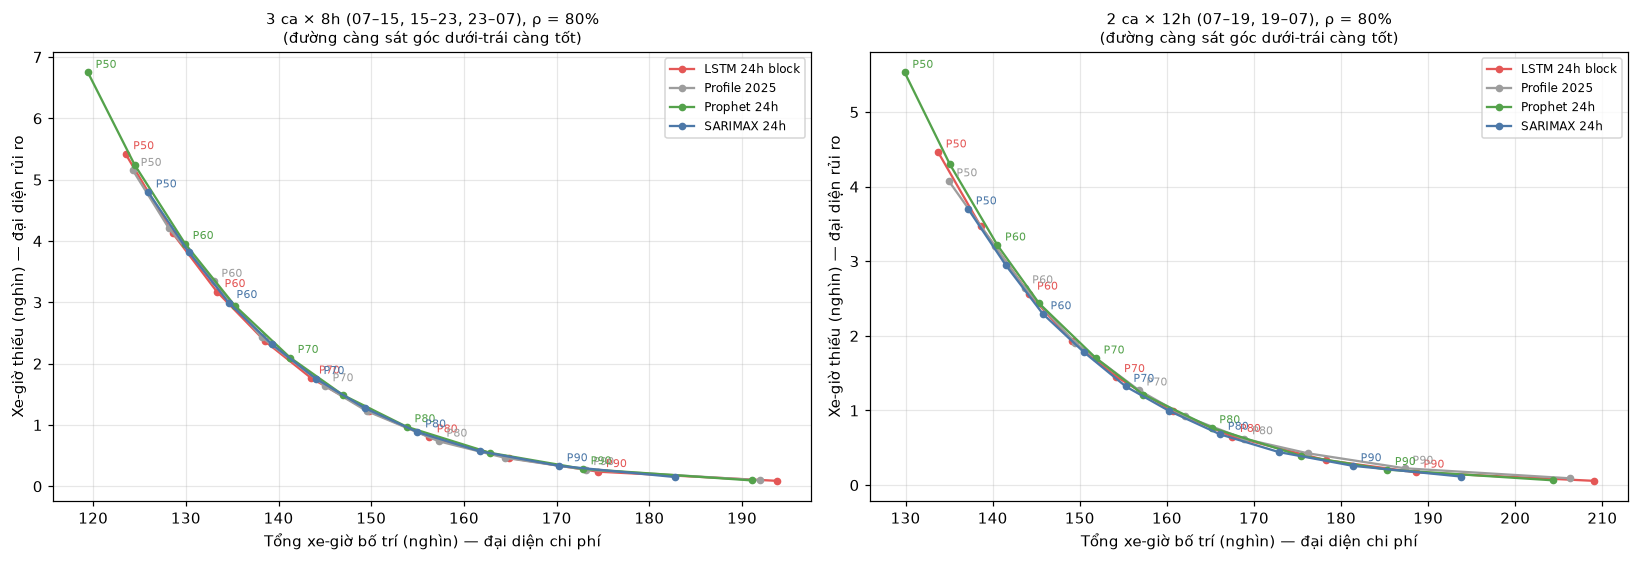

In [11]:
# 6.1 Đường đánh đổi chi phí – thiếu xe khi tăng phân vị kế hoạch (ρ cố định)
pattern0 = list(SHIFT_PATTERNS)[0]
colors = {"Profile 2025": "#9D9D9D", "SARIMAX 24h": "#4C78A8", "LSTM 24h block": "#E45756",
          "Prophet 24h": "#54A24B"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, pattern in zip(axes, SHIFT_PATTERNS):
    sub = eval_q[eval_q["Kiểu ca"] == pattern]
    for m, g in sub.groupby("Nguồn dự báo"):
        g = g.sort_values("Phân vị")
        ax.plot(g["Xe-giờ bố trí"] / 1e3, g["Xe-giờ thiếu"] / 1e3, marker="o", ms=4, color=colors[m], label=m)
        for _, r in g.iloc[::2].iterrows():
            ax.annotate(f"P{r['Phân vị'] * 100:.0f}", (r["Xe-giờ bố trí"] / 1e3, r["Xe-giờ thiếu"] / 1e3),
                        textcoords="offset points", xytext=(5, 3), fontsize=7, color=colors[m])
    ax.set_xlabel("Tổng xe-giờ bố trí (nghìn) — đại diện chi phí")
    ax.set_ylabel("Xe-giờ thiếu (nghìn) — đại diện rủi ro")
    ax.set_title(f"{pattern}, ρ = {RHO_BASE:.0%}\n(đường càng sát góc dưới-trái càng tốt)", fontsize=10)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "tradeoff_quantiles.png", dpi=150, bbox_inches="tight"); plt.show()

#### 🔎 Cách đọc biểu đồ đánh đổi
* **Trục ngang:** tổng nguồn lực bỏ ra (xe-giờ), đi sang phải là tốn kém hơn. **Trục dọc:** tổng xe-giờ thiếu, đi xuống là an toàn hơn.
* **Mỗi đường** là một nguồn dự báo; **mỗi điểm** trên đường là một phân vị (P50 ở đầu trái-trên, P95 ở cuối phải-dưới).
* Đường **nằm thấp hơn và lệch trái hơn** là tốt hơn: cùng chi phí thì ít thiếu xe hơn.
* **Các đường gần như chồng lên nhau** → các mô hình tương đương nhau khi dùng để xếp ca.
* **Hình dạng "khuỷu tay":** đoạn đầu (P50→P75) thêm ít xe mà giảm thiếu rất nhanh; đoạn cuối (P85→P95) thêm nhiều xe nhưng chỉ giảm thiếu chút ít. Vùng hợp lý thường nằm quanh **khuỷu**.
* So hai biểu đồ: các đường của 2 ca × 12h nằm **lệch phải** hơn, tức tốn nhiều xe-giờ hơn cho cùng mức thiếu.

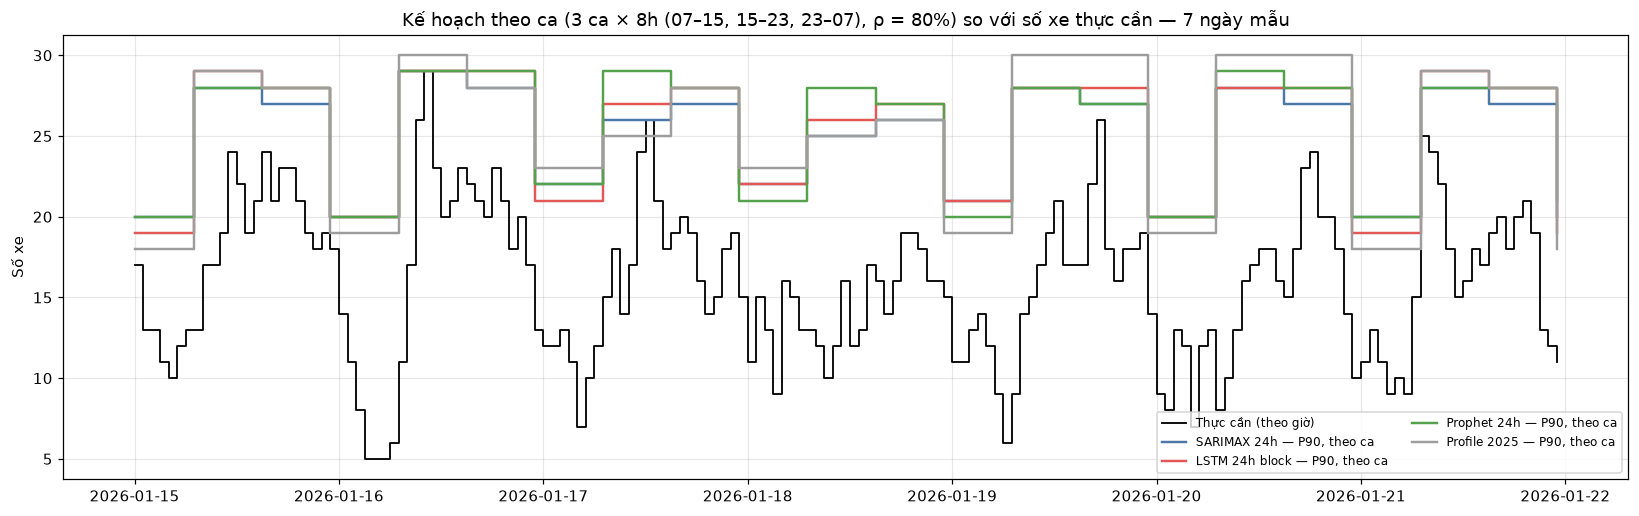

In [12]:
# 6.2 Timeline 7 ngày: số xe thực cần theo giờ vs kế hoạch theo ca (P90, ρ = RHO_BASE)
sl = slice(24 * 14, 24 * 21)
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.step(ts_test[sl], need[RHO_BASE][sl], where="post", color="black", lw=1.2, label="Thực cần (theo giờ)")
for m in [x for x in ["SARIMAX 24h", "LSTM 24h block", "Prophet 24h", "Profile 2025"] if x in MODELS]:
    plan_h, _ = shift_tables[(pattern0, m, "P90", RHO_BASE)]
    ax.step(ts_test[sl], plan_h.values[sl], where="post", color=colors[m], lw=1.6, label=f"{m} — P90, theo ca")
ax.set_ylabel("Số xe"); ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
ax.set_title(f"Kế hoạch theo ca ({pattern0}, ρ = {RHO_BASE:.0%}) so với số xe thực cần — 7 ngày mẫu")
fig.tight_layout(); fig.savefig(OUT_DIR / "timeline_7days.png", dpi=150, bbox_inches="tight"); plt.show()

#### 🔎 Cách đọc timeline 7 ngày
* **Đường đen** là số xe thực cần theo từng giờ, dao động mạnh từ giờ này sang giờ khác.
* **Các đường màu** là kế hoạch theo ca: dạng bậc thang, giữ nguyên trong mỗi ca 8 giờ.
* **Chỗ đường đen vượt lên trên đường màu** là các giờ thiếu xe, thường là những đỉnh đột biến ngắn mà không dự báo nào đoán trước được.
* **Khoảng trống lớn giữa đường màu và đường đen** (thường vào cuối ca, hoặc đêm khuya) là xe dư.

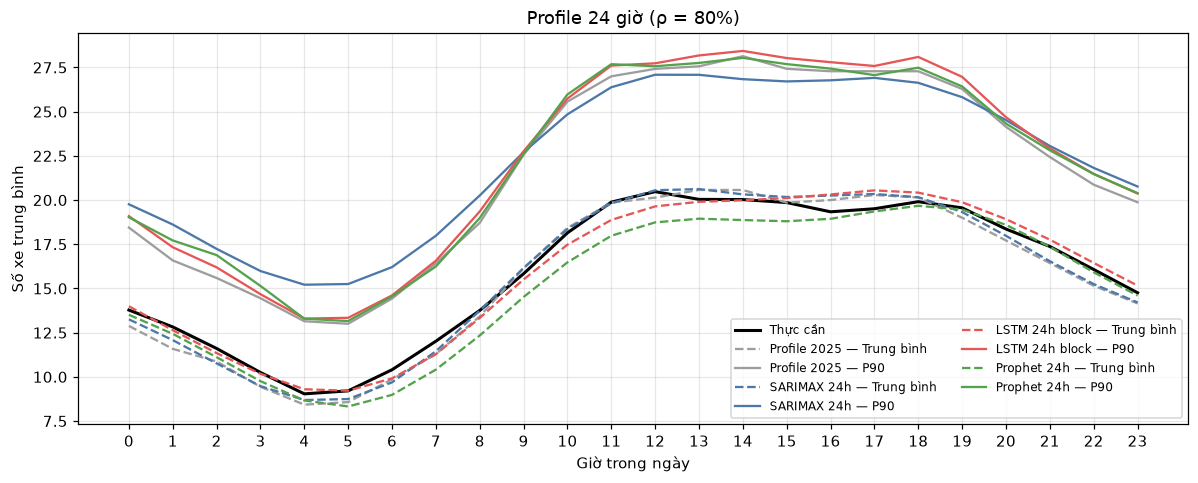

In [13]:
# 6.3 Profile 24 giờ: trung bình số xe thực cần vs kế hoạch theo giờ
fig, ax = plt.subplots(figsize=(11, 4.5))
hours = ts_test.hour
ax.plot(range(24), pd.Series(need[RHO_BASE]).groupby(hours).mean(), color="black", lw=2, label="Thực cần")
for m in MODELS:
    for basis, ls in [("Trung bình", "--"), ("P90", "-")]:
        ax.plot(range(24), pd.Series(hourly_plans[(m, basis, RHO_BASE)]).groupby(hours).mean(),
                color=colors[m], ls=ls, label=f"{m} — {basis}")
ax.set_xticks(range(24)); ax.set_xlabel("Giờ trong ngày"); ax.set_ylabel("Số xe trung bình")
ax.set_title(f"Profile 24 giờ (ρ = {RHO_BASE:.0%})"); ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(OUT_DIR / "hourly_profile.png", dpi=150, bbox_inches="tight"); plt.show()

#### 🔎 Cách đọc profile 24 giờ
* Trung bình theo **giờ trong ngày** trên toàn bộ 2026. **Đường đen** là số xe thực cần.
* **Nhu cầu thấp nhất khoảng 3–6h sáng, cao nhất buổi trưa đến chiều tối.** Đây là căn cứ chính để chia ca.
* **Đường nét đứt** (kế hoạch theo trung bình) bám sát hoặc nằm dưới đường đen → về trung bình là đủ, nhưng vẫn thiếu ở những ngày bận hơn bình thường.
* **Đường liền** (kế hoạch P90) nằm trên đường đen một khoảng gần như đều → phần dự phòng.
* Biểu đồ này chưa gộp theo ca, nên chỉ dùng để hiểu hình dạng nhu cầu trong ngày.

## Bước 7: Độ nhạy

### 7.1 Theo tỷ lệ chi phí thiếu / thừa
Chi phí tính theo đơn vị "xe-giờ thừa" (1 xe-giờ thừa = 1; 1 xe-giờ thiếu = $r$). Đây **không phải chi phí tiền thật**, chỉ để so các phương án khi chưa có số liệu chi phí.

In [14]:
cost_cols = [c for c in eval_shift.columns if c.startswith("Chi phí")]
sub = eval_shift[eval_shift["ρ_max"] == RHO_BASE].set_index(["Kiểu ca", "Nguồn dự báo", "Kế hoạch theo"])[cost_cols]
print(f"Chi phí tương đối theo ca, ρ = {RHO_BASE:.0%} (thấp hơn = tốt hơn); phương án tốt nhất mỗi cột:")
for c in cost_cols:
    best = sub[c].idxmin()
    print(f"  {c:<26}: {' / '.join(best)}  ({sub[c].min():,.0f})")
display(sub)

Chi phí tương đối theo ca, ρ = 80% (thấp hơn = tốt hơn); phương án tốt nhất mỗi cột:
  Chi phí (thiếu = 2× thừa) : 3 ca × 8h (07–15, 15–23, 23–07) / SARIMAX 24h / Trung bình  (32,165)
  Chi phí (thiếu = 3× thừa) : 3 ca × 8h (07–15, 15–23, 23–07) / Profile 2025 / Trung bình  (36,816)
  Chi phí (thiếu = 5× thừa) : 3 ca × 8h (07–15, 15–23, 23–07) / Profile 2025 / Trung bình  (45,872)
  Chi phí (thiếu = 10× thừa): 3 ca × 8h (07–15, 15–23, 23–07) / SARIMAX 24h / P90  (65,760)
  Chi phí (thiếu = 20× thừa): 3 ca × 8h (07–15, 15–23, 23–07) / SARIMAX 24h / P90  (69,090)


Chi phí (thiếu = 2× thừa)  Chi phí (thiếu = 3× thừa)  Chi phí (thiếu = 5× thừa)  Chi phí (thiếu = 10× thừa)  Chi phí (thiếu = 20× thừa)
Kiểu ca                         Nguồn dự báo   Kế hoạch theo                                                                                                                                         
3 ca × 8h (07–15, 15–23, 23–07) Profile 2025   Trung bình                     32,288.00                  36,816.00                  45,872.00                   68,512.00                  113,792.00
                                               P90                            65,774.00                  66,045.00                  66,587.00                   67,942.00                   70,652.00
                                SARIMAX 24h    Trung bình                     32,165.00                  36,964.00                  46,562.00                   70,557.00                  118,547.00
                                               P90                            63,096.00                  63,429.00                  64,095.00                   65,760.00                   69,090.00
                                LSTM 24h block Trung bình                     32,718.00                  37,533.00                  47,163.00                   71,238.00                  119,388.00
                                               P90                            67,043.00                  67,281.00                  67,757.00                   68,947.00                   71,327.00
                                Prophet 24h    Trung bình                     32,449.00                  39,016.00                  52,150.00                   84,985.00                  150,655.00
                                               P90                            65,527.00                  65,811.00                  66,379.00                   67,799.00                   70,639.00
2 ca × 12h (07–19, 19–07)       Profile 2025   Trung bình                     40,218.00                  43,891.00                  51,237.00                   69,602.00                  106,332.00
                                               P90                            79,826.00                  80,051.00                  80,501.00                   81,626.00                   83,876.00
                                SARIMAX 24h    Trung bình                     40,128.00                  43,829.00                  51,231.00                   69,736.00                  106,746.00
                                               P90                            73,979.00                  74,237.00                  74,753.00                   76,043.00                   78,623.00
                                LSTM 24h block Trung bình                     41,260.00                  45,196.00                  53,068.00                   72,748.00                  112,108.00
                                               P90                            80,930.00                  81,102.00                  81,446.00                   82,306.00                   84,026.00
                                Prophet 24h    Trung bình                     40,450.00                  45,612.00                  55,936.00                   81,746.00                  133,366.00
                                               P90                            77,754.00                  77,961.00                  78,375.00                   79,410.00                   81,480.00

#### 🔎 Cách đọc bảng chi phí
* **Mỗi cột** là một giả định về mức nghiêm trọng của việc thiếu xe (2×, 3×, …, 20× so với thừa xe). **Số nhỏ hơn là tốt hơn.** Chỉ so các số **trong cùng một cột**.
* Bảng này chỉ có hai cách lập (Trung bình và P90). Khi $r$ nhỏ, lập theo Trung bình rẻ hơn; khi $r$ lớn, P90 rẻ hơn. Phân vị ở giữa (Bước 5) thường còn tốt hơn cả hai.
* **Tỷ lệ $r$ là quyết định chính sách**, dữ liệu không tự trả lời được. Với EMS, thiếu xe ảnh hưởng tính mạng nên $r$ thường được coi là lớn.

### 7.2 Nếu thời gian bận năm 2026 khác năm 2025 ±20%
Kế hoạch vẫn lập với $E[S]$ của 2025, nhưng số xe thực cần tính với $E[S]$ thực tế bị lệch. Bảng cho biết kế hoạch chịu được sai lệch này đến đâu.

In [15]:
rows = []
for f in [0.8, 0.9, 1.0, 1.1, 1.2]:
    need_f = vehicles_needed(W_actual * f, RHO_BASE)
    for m in MODELS:
        for basis in ["Trung bình", "P90"]:
            plan_h, sid = shift_tables[(pattern0, m, basis, RHO_BASE)]
            r = evaluate_plan(plan_h.values, need_f, sid.values, cost_ratios=COST_RATIOS)
            rows.append({"E[S] thực tế": f"{f:.1f}× ({63.38 * f:.0f} phút)", "Nguồn dự báo": m,
                         "Kế hoạch theo": basis, "% ca có giờ thiếu": r["% ca có giờ thiếu"],
                         "Xe-giờ thiếu": r["Xe-giờ thiếu"]})
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / "sensitivity_service_time.csv", index=False)
print(f"{pattern0}, ρ = {RHO_BASE:.0%} — % ca có giờ thiếu xe:")
display(sens.pivot_table(index=["Nguồn dự báo", "Kế hoạch theo"], columns="E[S] thực tế", values="% ca có giờ thiếu"))

3 ca × 8h (07–15, 15–23, 23–07), ρ = 80% — % ca có giờ thiếu xe:


E[S] thực tế                  0.8× (51 phút)  0.9× (57 phút)  1.0× (63 phút)  1.1× (70 phút)  1.2× (76 phút)
Nguồn dự báo   Kế hoạch theo                                                                                
LSTM 24h block P90                      0.47            1.65            7.18           19.53           35.88
               Trung bình              20.71           43.53           68.71           86.12           92.82
Profile 2025   P90                      0.71            2.12            7.53           21.06           37.29
               Trung bình              20.00           42.35           69.29           87.88           94.71
Prophet 24h    P90                      0.59            2.00            9.06           21.29           38.82
               Trung bình              28.59           54.71           76.59           88.82           94.59
SARIMAX 24h    P90                      0.82            2.47            9.18           23.65           42.47
               Trung bình              20.59           45.41           68.82           87.88           94.47

#### 🔎 Cách đọc bảng độ nhạy thời gian bận
* **Cột giữa (1.0×)** là kết quả chính. **Cột trái** là trường hợp năm 2026 xe bận ngắn hơn 2025; **cột phải** là bận lâu hơn (ví dụ do kẹt xe, bệnh viện quá tải, thời gian bàn giao kéo dài).
* Kế hoạch vẫn lập với 63,38 phút, nên khi thời gian bận thực tế tăng, % ca thiếu xe **tăng rất nhanh**. Chỉ cần bận lâu hơn 10% (khoảng 70 phút) là kế hoạch P90 đã thiếu xe ở nhiều ca hơn hẳn.
* **Ý nghĩa vận hành:** $E[S]$ là tham số **quan trọng ngang với dự báo**. Nên theo dõi thời gian bận hàng tháng và cập nhật kế hoạch khi nó thay đổi.

### 7.3 Đối chiếu với tiêu chí hàng đợi (Erlang B, Poisson)
Cùng khối lượng công việc $W$ (kế hoạch P90), so số xe theo giới hạn $\rho$ với hai tiêu chí xét dao động ngẫu nhiên: Erlang B (xác suất hết xe ≤ 5%) và phân vị Poisson 98%. Đây là kiểm tra bổ sung, chưa dùng để đánh giá ở trên.

In [16]:
rows = []
for m in MODELS:
    W = W_plan[(m, "P90")]
    crit = {f"ρ ≤ {rho:.0%}": vehicles_needed(W, rho) for rho in RHO_LIST}
    crit["Erlang B ≤ 5%"] = vehicles_erlang_b(W, p_block=0.05)
    crit["Poisson 98%"] = vehicles_poisson_quantile(W, z=2.05)
    for name, s in crit.items():
        rows.append({"Nguồn dự báo": m, "Tiêu chí": name, "Xe TB": s.mean(), "Xe max": s.max()})
display(pd.DataFrame(rows).pivot_table(index="Tiêu chí", columns="Nguồn dự báo", values=["Xe TB", "Xe max"]).round(1))

Xe TB                                              Xe max                                     
Nguồn dự báo  LSTM 24h block Profile 2025 Prophet 24h SARIMAX 24h LSTM 24h block Profile 2025 Prophet 24h SARIMAX 24h
Tiêu chí                                                                                                             
Erlang B ≤ 5%          22.70        22.30       22.60       22.80          30.00        29.00       29.00       29.00
Poisson 98%            26.30        25.90       26.20       26.40          34.00        34.00       34.00       34.00
ρ ≤ 75%                23.60        23.10       23.50       23.70          32.00        32.00       32.00       32.00
ρ ≤ 80%                22.20        21.70       22.10       22.30          30.00        30.00       30.00       30.00
ρ ≤ 85%                20.90        20.50       20.80       21.00          29.00        28.00       28.00       28.00

#### 🔎 Cách đọc bảng tiêu chí hàng đợi
* Tất cả các dòng dùng **cùng khối lượng công việc** $W$ (kế hoạch P90), chỉ khác **quy tắc** đổi $W$ thành số xe:
  * **ρ ≤ 75/80/85%:** số xe $= W/\rho$. Đơn giản, dự phòng tỷ lệ thuận với $W$.
  * **Erlang B ≤ 5%:** chọn số xe nhỏ nhất sao cho xác suất **tất cả xe đều bận** khi có cuộc gọi mới ≤ 5%. Mô hình này tính cả dao động ngẫu nhiên của cuộc gọi.
  * **Poisson 98%:** đủ xe trong 98% tình huống ngẫu nhiên. Đây là tiêu chí khắt khe nhất.
* **Erlang B ≈ ρ ≤ 80%** ở đội xe cỡ 20–30 xe → quy tắc $\rho$ = 80% đang cho mức an toàn tương đương xác suất hết xe khoảng 5%.
* Riêng **ca đêm** (đội xe nhỏ), Erlang B đòi tỷ lệ dự phòng cao hơn $\rho$ → nếu muốn chặt chẽ hơn, có thể dùng Erlang B cho ca đêm.

## Bước 8: Tổng hợp & xuất kết quả

Phần tóm tắt dưới đây **được tính tự động** từ các bảng trên (không gõ tay số liệu), nên luôn khớp với lần chạy gần nhất.

In [17]:
cost_col = f"Chi phí (thiếu = {COST_RATIO}× thừa)"
base = eval_shift[eval_shift["ρ_max"] == RHO_BASE].copy()
best = base.loc[base[cost_col].idxmin()]
models_only = base[base["Nguồn dự báo"] != "Profile 2025"]
best_model = models_only.loc[models_only[cost_col].idxmin()]
ref = base[(base["Kiểu ca"] == best_model["Kiểu ca"]) & (base["Nguồn dự báo"] == "Profile 2025")
           & (base["Kế hoạch theo"] == best_model["Kế hoạch theo"])].iloc[0]

print("═" * 78)
print(f"TÓM TẮT (ρ = {RHO_BASE:.0%}, chi phí: 1 xe-giờ thiếu = {COST_RATIO} xe-giờ thừa)")
print("═" * 78)
print(f"1. Độ chính xác dự báo 24h tới (MAE): "
      + ", ".join(f"{m} {acc.loc[m, 'MAE']:.3f}" for m in MODELS))
for pattern in SHIFT_PATTERNS:
    print(f"\n2. {pattern}:")
    for basis in ["Trung bình", "P90"]:
        for m in MODELS:
            r = base[(base["Kiểu ca"] == pattern) & (base["Nguồn dự báo"] == m) & (base["Kế hoạch theo"] == basis)].iloc[0]
            print(f"   {m:<15} {basis:<10}: {r['Xe-giờ bố trí']:>8,.0f} xe-giờ | thiếu {r['Xe-giờ thiếu']:>6,.0f} xe-giờ"
                  f" | {r['% ca có giờ thiếu']:5.1f}% ca có giờ thiếu | chi phí {r[cost_col]:>8,.0f}")
print(f"\n3. Phương án chi phí thấp nhất: {best['Nguồn dự báo']} — {best['Kế hoạch theo']} — {best['Kiểu ca']}"
      f" (chi phí {best[cost_col]:,.0f})")
saving = (1 - best_model[cost_col] / ref[cost_col]) * 100
print(f"   Mô hình dự báo tốt nhất: {best_model['Nguồn dự báo']} — {best_model['Kế hoạch theo']} — {best_model['Kiểu ca']}"
      f": chi phí {best_model[cost_col]:,.0f} vs baseline Profile 2025 cùng cách lập {ref[cost_col]:,.0f}"
      f" → {'giảm' if saving > 0 else 'tăng'} {abs(saving):.1f}%")
sz = shift_size[(shift_size["Kiểu ca"] == best["Kiểu ca"]) & (shift_size["Nguồn dự báo"] == best["Nguồn dự báo"])
                & (shift_size["Kế hoạch theo"] == best["Kế hoạch theo"])]
print("   Số xe mỗi ca (TB [ít nhất–nhiều nhất]): "
      + "; ".join(f"ca {r['Ca bắt đầu']}: {r['Xe TB']:.1f} [{r['Ít nhất']:.0f}–{r['Nhiều nhất']:.0f}]" for _, r in sz.iterrows()))

bq = best_q[(best_q["Tỷ lệ chi phí"] == f"thiếu = {COST_RATIO}× thừa")]
print(f"\n4. Nếu chọn phân vị kế hoạch tối ưu (Bước 5), thiếu = {COST_RATIO}× thừa:")
for _, r in bq.sort_values(["Kiểu ca", "Chi phí"]).iterrows():
    print(f"   {r['Kiểu ca'].split(' (')[0]:<10} {r['Nguồn dự báo']:<15}: P{r['Phân vị tốt nhất'] * 100:.0f} → chi phí {r['Chi phí']:>8,.0f}"
          f" | {r['Xe-giờ bố trí']:>8,.0f} xe-giờ | {r['% ca có giờ thiếu']:5.1f}% ca có giờ thiếu")

# Xuất lịch xe theo giờ của mọi phương án (ρ = RHO_BASE)
export = pd.DataFrame({"timestamp": ts_test, "actual_dispatches": y_test.values,
                       "workload_actual": W_actual, "need_actual": need[RHO_BASE]})
for (m, basis), W in W_plan.items():
    export[f"plan_hourly | {m} | {basis}"] = hourly_plans[(m, basis, RHO_BASE)]
    for pattern in SHIFT_PATTERNS:
        export[f"plan_shift | {pattern.split(' (')[0]} | {m} | {basis}"] = shift_tables[(pattern, m, basis, RHO_BASE)][0].values
export.to_csv(OUT_DIR / "vehicle_plans_hourly.csv", index=False)
print(f"\nĐã lưu bảng & biểu đồ vào: {OUT_DIR}")

══════════════════════════════════════════════════════════════════════════════
TÓM TẮT (ρ = 80%, chi phí: 1 xe-giờ thiếu = 3 xe-giờ thừa)
══════════════════════════════════════════════════════════════════════════════
1. Độ chính xác dự báo 24h tới (MAE): Profile 2025 3.042, SARIMAX 24h 2.997, LSTM 24h block 3.009, Prophet 24h 3.050

2. 3 ca × 8h (07–15, 15–23, 23–07):
   Profile 2025    Trung bình:  126,864 xe-giờ | thiếu  4,528 xe-giờ |  69.3% ca có giờ thiếu | chi phí   36,816
   SARIMAX 24h     Trung bình:  125,928 xe-giờ | thiếu  4,799 xe-giờ |  68.8% ca có giờ thiếu | chi phí   36,964
   LSTM 24h block  Trung bình:  126,433 xe-giờ | thiếu  4,815 xe-giờ |  68.7% ca có giờ thiếu | chi phí   37,533
   Prophet 24h     Trung bình:  120,908 xe-giờ | thiếu  6,567 xe-giờ |  76.6% ca có giờ thiếu | chi phí   39,016
   Profile 2025    P90       :  173,121 xe-giờ | thiếu    271 xe-giờ |   7.5% ca có giờ thiếu | chi phí   66,045
   SARIMAX 24h     P90       :  170,257 xe-giờ | thiếu    333 xe

#### 🔎 Cách dùng phần tóm tắt để ra quyết định
1. **Mục 1** cho thấy độ chính xác dự báo; các nguồn gần như ngang nhau.
2. **Mục 2** so hai cách lập cực đoan: theo Trung bình (ít xe, thiếu nhiều) và theo P90 (nhiều xe, hiếm thiếu), với cả hai kiểu ca.
3. **Mục 3** nêu phương án rẻ nhất theo tỷ lệ chi phí đang chọn (`COST_RATIO`), và cho biết mô hình dự báo có thực sự hơn baseline hay không.
4. **Mục 4** cho thấy nếu chọn phân vị tối ưu thì chi phí và rủi ro là bao nhiêu.

**Các quyết định nhóm cần chốt:** (a) tỷ lệ chi phí $r$, hoặc mức "% ca được phép thiếu xe"; (b) mức $\rho_{max}$; (c) kiểu ca. Sau khi chốt, sửa các biến ở cell cấu hình đầu notebook rồi **Run All**.

### Hạn chế cần ghi trong báo cáo
* **$\rho_{max}$ chỉ là kịch bản**: cùng một mức $\rho$, đội xe nhỏ (ca đêm) rủi ro hết xe cao hơn đội xe lớn. Bảng 7.3 (Erlang B) cho thấy mức chênh.
* **Chi phí là tương đối** (đơn vị xe-giờ), chưa phải tiền thật; kết luận "phương án tốt nhất" thay đổi theo tỷ lệ thiếu/thừa (Bảng 7.1 và Bước 5).
* **Cận trên P90 của các nguồn được tạo khác nhau** (SARIMAX dùng khoảng tin cậy của mô hình; LSTM và Profile dùng phân vị thực nghiệm năm 2025). Xem cột "Độ phủ P90" ở Bước 1 để biết cận trên nào đúng mức hơn.
* **Mốc dữ liệu học khác nhau**: SARIMAX fit lại trên 2025; LSTM và Prophet chỉ học 2019–2024 (Prophet vẫn dùng số thực tế 2025 làm lịch sử đặc trưng).
* Chưa mô hình hóa vị trí trạm, thời gian di chuyển, hay ưu tiên cuộc gọi; số xe ở đây là **số xe sẵn sàng toàn thành phố**.